# EDA | Índice Nacional de Precios al Consumidor (INPC)

## 1 | Pregunta y decisiones

**¿Cómo se ha comportado la inflación general en México desde 2013 y en qué meses se desvió de lo habitual?**

Se usa el INPC general nacional mensual del INEGI (base 2a quincena de julio de 2018 = 100). Es la serie que luego sirve para deflactar los precios de la cadena del maíz.

Decisiones de análisis:

- **Ventana:** enero de 2013 al último mes publicado. Las variaciones se calcularon sobre la serie completa de la fuente, así que 2013 ya tiene variación anual.
- **Periodos de alta inflación a examinar:** 2017 y 2021–2023.
- **Anomalías:** se aplican dos técnicas a la variación mensual, rango intercuartílico (IQR) y z-score robusto (mediana y MAD), y se comparan.
- **Alcance:** solo el índice general; no se usan índices genéricos (tortilla, maíz).

## 2 | Fuente y cobertura

In [1]:
# Importamos herramientas y fijamos una presentación común.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown

AZUL, OCRE, GRIS, VERDE, ROJO = "#1f4e79", "#c27c0e", "#7f8c8d", "#2e7d5b", "#a93226"
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

raiz = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed" / "inpc_mensual.csv").is_file()),
    None,
)
if raiz is None:
    raise FileNotFoundError("Abre la libreta dentro del repositorio con los datos procesados.")
FIG = raiz / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(FIG / f"inpc_eda_{nombre}.png", dpi=150, bbox_inches="tight")

H = {}  # cifras que se reutilizan en la síntesis
PERIODOS = {"2017": ("2017-01-01", "2017-12-01"), "2021–2023": ("2021-01-01", "2023-12-01")}

In [2]:
# Cargamos la serie procesada y verificamos su integridad.
inpc = pd.read_csv(raiz / "data/processed/inpc_mensual.csv", parse_dates=["fecha"])
assert set(inpc["serie"]) == {"general"}
inpc = inpc.set_index("fecha").sort_index()
assert not inpc.index.duplicated().any() and (inpc["indice"] > 0).all()

esperado = pd.date_range(inpc.index.min(), inpc.index.max(), freq="MS")
faltan = esperado.difference(inpc.index)
base = inpc.loc["2018-07":"2018-08", "indice"]
H.update(ini=inpc.index.min(), fin=inpc.index.max(), n=len(inpc), n_esp=len(esperado), n_faltan=len(faltan),
         base_media=base.mean())

display(pd.DataFrame({
    "valores": [inpc[c].notna().sum() for c in ["indice", "var_mensual_pct", "var_anual_pct"]],
    "faltantes": [inpc[c].isna().sum() for c in ["indice", "var_mensual_pct", "var_anual_pct"]],
}, index=["índice", "variación mensual", "variación anual"]))
display(Markdown(
    f"La serie va de **{H['ini']:%Y-%m}** a **{H['fin']:%Y-%m}**: {H['n']} meses de {H['n_esp']} posibles "
    f"({H['n_faltan']} faltantes), sin duplicados y sin valores nulos en las tres columnas. "
    f"El índice promedia {H['base_media']:.1f} en julio–agosto de 2018, consistente con la base. "
    f"El último año ({H['fin'].year}) está incompleto: {inpc.loc[str(H['fin'].year)].shape[0]} meses."
))

,valores,faltantes
índice,166,0
variación mensual,166,0
variación anual,166,0


La serie va de **2013-01** a **2026-10**: 166 meses de 166 posibles (0 faltantes), sin duplicados y sin valores nulos en las tres columnas. El índice promedia 100.2 en julio–agosto de 2018, consistente con la base. El último año (2026) está incompleto: 10 meses.

## 3 | Nivel del índice

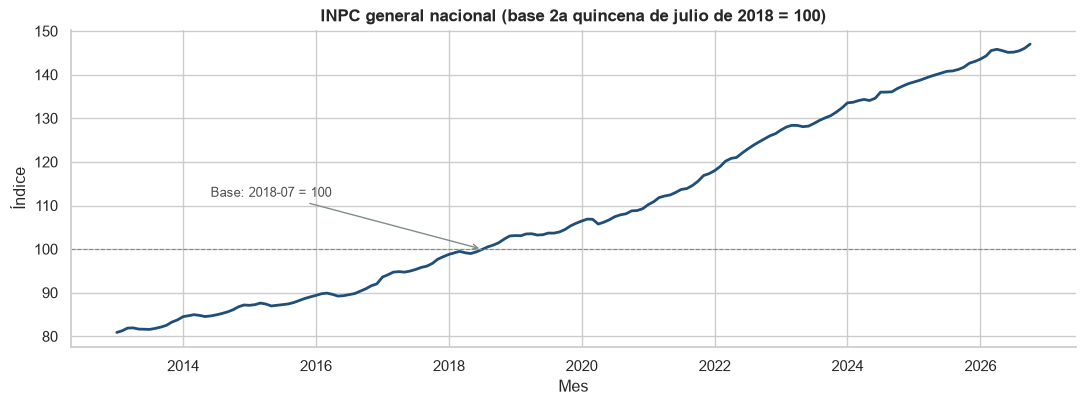

El índice pasó de 80.9 (2013-01) a 147.0 (2026-10): **+82 %** acumulado, 4.4 % anual compuesto.

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(inpc.index, inpc["indice"], color=AZUL, lw=2)
ax.axhline(100, color=GRIS, lw=0.8, ls="--")
ax.annotate("Base: 2018-07 = 100", xy=(pd.Timestamp("2018-07-01"), 100), xytext=(pd.Timestamp("2014-06-01"), 112),
            arrowprops=dict(arrowstyle="->", color=GRIS), color="0.3", fontsize=9)
ax.set_title("INPC general nacional (base 2a quincena de julio de 2018 = 100)")
ax.set_ylabel("Índice"); ax.set_xlabel("Mes")
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); guardar(fig, "indice"); plt.show()

H.update(i0=inpc["indice"].iloc[0], i1=inpc["indice"].iloc[-1])
H["acum"] = (H["i1"] / H["i0"] - 1) * 100
H["cagr"] = ((H["i1"] / H["i0"]) ** (12 / (len(inpc) - 1)) - 1) * 100
display(Markdown(
    f"El índice pasó de {H['i0']:.1f} ({H['ini']:%Y-%m}) a {H['i1']:.1f} ({H['fin']:%Y-%m}): "
    f"**+{H['acum']:.0f} %** acumulado, {H['cagr']:.1f} % anual compuesto."
))

## 4 | Inflación mensual y anual

### 4.1 | Variación mensual y variación contra el mismo mes del año anterior

Las franjas grises marcan 2017 y 2021–2023.

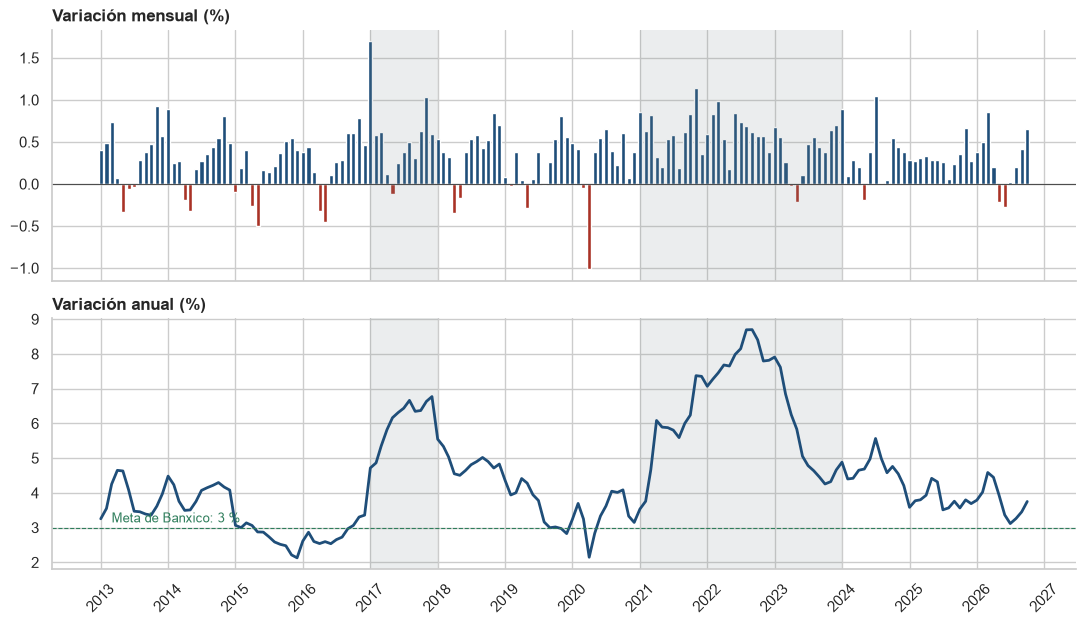

La inflación anual alcanzó su máximo en **2022-09** (8.70 %) y su mínimo en 2015-12 (2.13 %). La variación mensual mediana es 0.38 %.

In [4]:
def sombrear(ax):
    for ini, fin in PERIODOS.values():
        ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fin) + pd.offsets.MonthEnd(0), color=GRIS, alpha=0.15, lw=0)

fig, axs = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
colores = np.where(inpc["var_mensual_pct"] >= 0, AZUL, ROJO)
axs[0].bar(inpc.index, inpc["var_mensual_pct"], width=22, color=colores)
axs[0].axhline(0, color="0.3", lw=0.8)
axs[0].set_title("Variación mensual (%)", loc="left"); sombrear(axs[0])
axs[1].plot(inpc.index, inpc["var_anual_pct"], color=AZUL, lw=2)
axs[1].axhline(3, color=VERDE, lw=0.8, ls="--"); axs[1].text(inpc.index[2], 3.15, "Meta de Banxico: 3 %", color=VERDE, fontsize=9)
axs[1].set_title("Variación anual (%)", loc="left"); sombrear(axs[1])
axs[1].xaxis.set_major_locator(mdates.YearLocator(1)); axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.setp(axs[1].get_xticklabels(), rotation=45)
plt.tight_layout(); guardar(fig, "inflacion"); plt.show()

pico = inpc["var_anual_pct"].idxmax()
H.update(pico_m=pico, pico_v=inpc.loc[pico, "var_anual_pct"], min_v=inpc["var_anual_pct"].min(),
         min_m=inpc["var_anual_pct"].idxmin(), med_m=inpc["var_mensual_pct"].median())
display(Markdown(
    f"La inflación anual alcanzó su máximo en **{H['pico_m']:%Y-%m}** ({H['pico_v']:.2f} %) y su mínimo en "
    f"{H['min_m']:%Y-%m} ({H['min_v']:.2f} %). La variación mensual mediana es {H['med_m']:.2f} %."
))

### 4.2 | Inflación por año

Inflación de diciembre a diciembre y promedio anual del índice (el que se usa para deflactar). El último año está incompleto: su inflación es la del último mes disponible contra el mismo mes del año anterior.

,indice_prom,meses,inflacion_cierre_pct,prom_sobre_prom_pct
fecha,,,,
2013,82.04,12,3.97,NaN
2014,85.33,12,4.08,4.02
2015,87.65,12,2.13,2.72
2016,90.13,12,3.36,2.82
2017,95.57,12,6.77,6.04
2018,100.26,12,4.83,4.90
2019,103.90,12,2.83,3.64
2020,107.43,12,3.15,3.40
2021,113.54,12,7.36,5.69


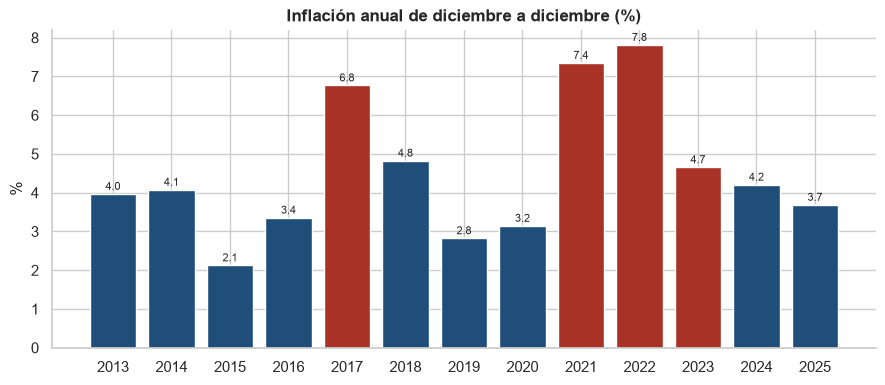

En rojo, los años de alta inflación. 2017 cerró en 6.8 %; 2021, 2022 y 2023 cerraron en 7.4 %, 7.8 % y 4.7 %.

In [5]:
anual = inpc.groupby(inpc.index.year).agg(indice_prom=("indice", "mean"), meses=("indice", "size"))
ultimo = inpc.groupby(inpc.index.year)["var_anual_pct"].last()
anual["inflacion_cierre_pct"] = ultimo
anual["prom_sobre_prom_pct"] = anual["indice_prom"].pct_change() * 100
display(anual.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
completos = anual[anual["meses"] == 12]
cols = [ROJO if a in (2017, 2021, 2022, 2023) else AZUL for a in completos.index]
ax.bar(completos.index, completos["inflacion_cierre_pct"], color=cols)
for x, v in zip(completos.index, completos["inflacion_cierre_pct"]):
    ax.text(x, v + 0.1, f"{v:.1f}", ha="center", fontsize=8)
ax.set_xticks(completos.index); ax.set_title("Inflación anual de diciembre a diciembre (%)")
ax.set_ylabel("%")
plt.tight_layout(); guardar(fig, "inflacion_anual"); plt.show()
H["anual"] = anual
display(Markdown(
    f"En rojo, los años de alta inflación. 2017 cerró en {anual.loc[2017, 'inflacion_cierre_pct']:.1f} %; "
    f"2021, 2022 y 2023 cerraron en {anual.loc[2021, 'inflacion_cierre_pct']:.1f} %, "
    f"{anual.loc[2022, 'inflacion_cierre_pct']:.1f} % y {anual.loc[2023, 'inflacion_cierre_pct']:.1f} %."
))

## 5 | Periodos de alta inflación

In [6]:
fila = []
for nombre, (ini, fin) in PERIODOS.items():
    p = inpc.loc[ini:fin]
    fila.append({"periodo": nombre, "meses": len(p), "anual_media_pct": p["var_anual_pct"].mean(),
                 "anual_max_pct": p["var_anual_pct"].max(), "mes_max": p["var_anual_pct"].idxmax().strftime("%Y-%m"),
                 "mensual_media_pct": p["var_mensual_pct"].mean()})
resto = inpc[~inpc.index.isin(pd.concat([inpc.loc[a:b] for a, b in PERIODOS.values()]).index)]
fila.append({"periodo": "resto", "meses": len(resto), "anual_media_pct": resto["var_anual_pct"].mean(),
             "anual_max_pct": resto["var_anual_pct"].max(), "mes_max": resto["var_anual_pct"].idxmax().strftime("%Y-%m"),
             "mensual_media_pct": resto["var_mensual_pct"].mean()})
per = pd.DataFrame(fila).set_index("periodo")
display(per.round(2))
H["per"] = per
display(Markdown(
    f"En 2017 la inflación anual promedió {per.loc['2017', 'anual_media_pct']:.1f} % (máximo {per.loc['2017', 'anual_max_pct']:.1f} % en {per.loc['2017', 'mes_max']}); "
    f"en 2021–2023 promedió {per.loc['2021–2023', 'anual_media_pct']:.1f} % (máximo {per.loc['2021–2023', 'anual_max_pct']:.1f} % en {per.loc['2021–2023', 'mes_max']}). "
    f"Fuera de esos periodos promedió {per.loc['resto', 'anual_media_pct']:.1f} %."
))

,meses,anual_media_pct,anual_max_pct,mes_max,mensual_media_pct
periodo,,,,,
2017,12,6.04,6.77,2017-12,0.55
2021–2023,36,6.38,8.70,2022-09,0.53
resto,118,3.76,5.57,2024-07,0.29


En 2017 la inflación anual promedió 6.0 % (máximo 6.8 % en 2017-12); en 2021–2023 promedió 6.4 % (máximo 8.7 % en 2022-09). Fuera de esos periodos promedió 3.8 %.

## 6 | Anomalías en la variación mensual

Se aplican dos técnicas a `var_mensual_pct`:

- **IQR:** anómalo si cae fuera de Q1 − 1.5·IQR o Q3 + 1.5·IQR.
- **z-score robusto:** z = 0.6745·(x − mediana)/MAD; anómalo si |z| > 3.5.

Ambas usan estadísticos resistentes a valores extremos. Como la inflación mensual tiene estacionalidad y cambia de régimen, una marca es un mes inusual frente a toda la serie, no un error de datos.

,var_mensual_pct,z_robusto,marca_iqr,marca_z_robusto,ambas_tecnicas,en_periodo
fecha,,,,,,
2015-05,-0.50,-3.08,True,False,False,False
2016-05,-0.45,-2.89,True,False,False,False
2017-01,1.70,4.61,True,True,True,True
2020-04,-1.01,-4.87,True,True,True,False


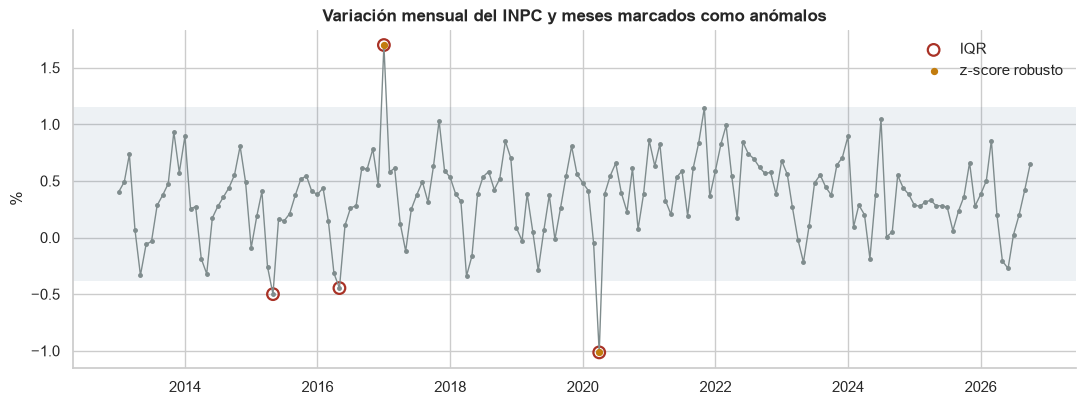

Banda IQR: [-0.39 %, 1.15 %]; MAD = 0.193. El IQR marca **4** meses, el z-score robusto **2**, coinciden en **2**; 4 meses en total; 1 en 2017 o 2021–2023.

In [7]:
x = inpc["var_mensual_pct"]
q1, q3 = x.quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mad = (x - x.median()).abs().median()
z = 0.6745 * (x - x.median()) / mad
anom = pd.DataFrame({"var_mensual_pct": x, "z_robusto": z,
                     "iqr": (x < lim_inf) | (x > lim_sup), "zrob": z.abs() > 3.5})
anom["ambas"] = anom["iqr"] & anom["zrob"]
marcados = anom[anom["iqr"] | anom["zrob"]].copy()
marcados["en_periodo"] = [any(pd.Timestamp(a) <= f <= pd.Timestamp(b) for a, b in PERIODOS.values()) for f in marcados.index]
H.update(lim_inf=lim_inf, lim_sup=lim_sup, mad=mad, n_iqr=int(anom["iqr"].sum()), n_z=int(anom["zrob"].sum()),
         n_ambas=int(anom["ambas"].sum()), n_union=len(marcados), n_en_periodo=int(marcados["en_periodo"].sum()))

display(marcados.assign(fecha=marcados.index.strftime("%Y-%m")).set_index("fecha")
        .rename(columns={"iqr": "marca_iqr", "zrob": "marca_z_robusto", "ambas": "ambas_tecnicas"}).round(2))

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(x.index, x, color=GRIS, lw=1, marker="o", ms=2.5)
ax.axhspan(lim_inf, lim_sup, color=AZUL, alpha=0.08, lw=0)
solo_z = anom[anom["zrob"] & ~anom["iqr"]]
ax.scatter(anom[anom["iqr"]].index, anom[anom["iqr"]]["var_mensual_pct"], s=70, facecolors="none", edgecolors=ROJO, lw=1.6, label="IQR")
ax.scatter(anom[anom["zrob"]].index, anom[anom["zrob"]]["var_mensual_pct"], s=18, color=OCRE, zorder=3, label="z-score robusto")
ax.set_title("Variación mensual del INPC y meses marcados como anómalos")
ax.set_ylabel("%"); ax.legend(frameon=False)
plt.tight_layout(); guardar(fig, "anomalias"); plt.show()

display(Markdown(
    f"Banda IQR: [{H['lim_inf']:.2f} %, {H['lim_sup']:.2f} %]; MAD = {H['mad']:.3f}. "
    f"El IQR marca **{H['n_iqr']}** meses, el z-score robusto **{H['n_z']}**, coinciden en **{H['n_ambas']}**; "
    f"{H['n_union']} meses en total; {H['n_en_periodo']} en 2017 o 2021–2023."
))

## 7 | Síntesis

In [8]:
display(Markdown(
    "**Hallazgos**\n\n"
    f"1. **Serie completa.** {H['n']} meses sin faltantes ni duplicados ({H['ini']:%Y-%m} a {H['fin']:%Y-%m}); "
    f"el nivel creció {H['acum']:.0f} % ({H['cagr']:.1f} % anual compuesto).\n"
    f"2. **Dos episodios de inflación alta.** 2017 (promedio anual {H['per'].loc['2017', 'anual_media_pct']:.1f} %) y "
    f"2021–2023 (promedio {H['per'].loc['2021–2023', 'anual_media_pct']:.1f} %, máximo {H['per'].loc['2021–2023', 'anual_max_pct']:.1f} % en {H['per'].loc['2021–2023', 'mes_max']}), "
    f"frente a {H['per'].loc['resto', 'anual_media_pct']:.1f} % en el resto del periodo.\n"
    f"3. **Anomalías.** Las dos técnicas coinciden en {H['n_ambas']} meses; en total se marcan {H['n_union']}; {H['n_en_periodo']} dentro de 2017 o 2021–2023.\n\n"
    "**Limitaciones.** Es el índice general: no refleja la canasta de un hogar que gasta más en alimentos. "
    "La variación mensual tiene estacionalidad que las técnicas no corrigen. El último año está incompleto."
))

**Hallazgos**

1. **Serie completa.** 166 meses sin faltantes ni duplicados (2013-01 a 2026-10); el nivel creció 82 % (4.4 % anual compuesto).
2. **Dos episodios de inflación alta.** 2017 (promedio anual 6.0 %) y 2021–2023 (promedio 6.4 %, máximo 8.7 % en 2022-09), frente a 3.8 % en el resto del periodo.
3. **Anomalías.** Las dos técnicas coinciden en 2 meses; en total se marcan 4; 1 dentro de 2017 o 2021–2023.

**Limitaciones.** Es el índice general: no refleja la canasta de un hogar que gasta más en alimentos. La variación mensual tiene estacionalidad que las técnicas no corrigen. El último año está incompleto.